In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style="whitegrid")

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Display plots inside the notebook
%matplotlib inline

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv(r"C:\Users\shrut\Downloads\retail_sales_dataset.csv")

In [3]:
# Display the number of rows and columns
print("Dataset Shape:", df.shape)

print("\nNumber of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display data types
print("\nColumn Data Types:")
print(df.dtypes)

# Display dataset information
print("\nDataset Information:")
df.info()

# Display first five rows
print("\nFirst Five Rows:")
display(df.head())

# Display last five rows
print("\nLast Five Rows:")
display(df.tail())

Dataset Shape: (1000, 9)

Number of Rows: 1000
Number of Columns: 9

Column Names:
['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age', 'Product Category', 'Quantity', 'Price per Unit', 'Total Amount']

Column Data Types:
Transaction ID       int64
Date                object
Customer ID         object
Gender              object
Age                  int64
Product Category    object
Quantity             int64
Price per Unit       int64
Total Amount         int64
dtype: object

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Transaction ID    1000 non-null   int64 
 1   Date              1000 non-null   object
 2   Customer ID       1000 non-null   object
 3   Gender            1000 non-null   object
 4   Age               1000 non-null   int64 
 5   Product Category  1000 non-null   object
 6   Quantity       

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100



Last Five Rows:


,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
995,996,2023-05-16,CUST996,Male,62,Clothing,1,50,50
996,997,2023-11-17,CUST997,Male,52,Beauty,3,30,90
997,998,2023-10-29,CUST998,Female,23,Beauty,4,25,100
998,999,2023-12-05,CUST999,Female,36,Electronics,3,50,150
999,1000,2023-04-12,CUST1000,Male,47,Electronics,4,30,120


In [4]:
# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)

# Calculate missing-value percentages
missing_percentage = (
    df.isnull().mean() * 100
).round(2)

print("\nMissing Value Percentage:")
print(missing_percentage)

# Check for duplicate rows
print("\nNumber of Duplicate Rows:", df.duplicated().sum())

Missing Values in Each Column:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Missing Value Percentage:
Transaction ID      0.0
Date                0.0
Customer ID         0.0
Gender              0.0
Age                 0.0
Product Category    0.0
Quantity            0.0
Price per Unit      0.0
Total Amount        0.0
dtype: float64

Number of Duplicate Rows: 0


In [5]:
# Create a copy of the original dataset
df = df.copy()

# Remove duplicate rows
duplicate_count = df.duplicated().sum()
df = df.drop_duplicates()

print("Duplicate rows removed:", duplicate_count)

# Convert Date column to datetime
df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

# Convert numerical columns to numeric data types
numeric_columns = [
    "Transaction ID",
    "Age",
    "Quantity",
    "Price per Unit",
    "Total Amount"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Check missing values after conversion
print("\nMissing values after conversion:")
print(df.isnull().sum())

# Display updated data types
print("\nUpdated data types:")
print(df.dtypes)

Duplicate rows removed: 0

Missing values after conversion:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64

Updated data types:
Transaction ID               int64
Date                datetime64[ns]
Customer ID                 object
Gender                      object
Age                          int64
Product Category            object
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object


In [6]:
required_columns = [
    "Date",
    "Gender",
    "Age",
    "Product Category",
    "Quantity",
    "Price per Unit",
    "Total Amount"
]

rows_before = len(df)

df = df.dropna(subset=required_columns).copy()

print("Rows before removing missing values:", rows_before)
print("Rows after removing missing values:", len(df))
print("Rows removed:", rows_before - len(df))

Rows before removing missing values: 1000
Rows after removing missing values: 1000
Rows removed: 0


In [7]:
# Calculate the expected transaction amount
df["Calculated Amount"] = (
    df["Quantity"] * df["Price per Unit"]
)

# Calculate the difference
df["Amount Difference"] = (
    df["Total Amount"] - df["Calculated Amount"]
).round(2)

print("Number of transactions with amount differences:",
      (df["Amount Difference"].abs() > 0.01).sum())

display(
    df[
        [
            "Quantity",
            "Price per Unit",
            "Total Amount",
            "Calculated Amount",
            "Amount Difference"
        ]
    ].head(10)
)

Number of transactions with amount differences: 0


,Quantity,Price per Unit,Total Amount,Calculated Amount,Amount Difference
0,3,50,150,150,0
1,2,500,1000,1000,0
2,1,30,30,30,0
3,1,500,500,500,0
4,2,50,100,100,0
5,1,30,30,30,0
6,2,25,50,50,0
7,4,25,100,100,0
8,2,300,600,600,0
9,4,50,200,200,0


In [8]:
# Extract year, month, quarter, and day of the week
df["Year"] = df["Date"].dt.year

df["Month"] = df["Date"].dt.month

df["Month Name"] = df["Date"].dt.strftime("%b")

df["Quarter"] = df["Date"].dt.to_period("Q").astype(str)

df["Day of Week"] = df["Date"].dt.day_name()

# Create customer age groups
age_bins = [0, 18, 25, 35, 45, 55, 65, 120]

age_labels = [
    "Under 18",
    "18-24",
    "25-34",
    "35-44",
    "45-54",
    "55-64",
    "65+"
]

df["Age Group"] = pd.cut(
    df["Age"],
    bins=age_bins,
    labels=age_labels,
    right=False
)

# Display the updated dataset
display(df.head())

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount,Calculated Amount,Amount Difference,Year,Month,Month Name,Quarter,Day of Week,Age Group
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150,150,0,2023,11,Nov,2023Q4,Friday,25-34
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000,1000,0,2023,2,Feb,2023Q1,Monday,25-34
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30,30,0,2023,1,Jan,2023Q1,Friday,45-54
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500,500,0,2023,5,May,2023Q2,Sunday,35-44
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100,100,0,2023,5,May,2023Q2,Saturday,25-34


In [9]:
# Select numerical columns
numerical_df = df.select_dtypes(include=np.number)

# Calculate mean
mean_values = numerical_df.mean()

# Calculate median
median_values = numerical_df.median()

# Calculate mode
mode_values = numerical_df.mode().iloc[0]

# Calculate standard deviation
std_values = numerical_df.std()

# Combine statistics into a single table
descriptive_stats = pd.DataFrame({
    "Mean": mean_values,
    "Median": median_values,
    "Mode": mode_values,
    "Standard Deviation": std_values
})

display(descriptive_stats.round(2))

,Mean,Median,Mode,Standard Deviation
Transaction ID,500.50,500.5,1.0,288.82
Age,41.39,42.0,43.0,13.68
Quantity,2.51,3.0,4.0,1.13
Price per Unit,179.89,50.0,50.0,189.68
Total Amount,456.00,135.0,50.0,560.00
Calculated Amount,456.00,135.0,50.0,560.00
Amount Difference,0.00,0.0,0.0,0.00
Year,2023.00,2023.0,2023.0,0.04
Month,6.55,6.0,5.0,3.45


In [10]:
# Detailed descriptive statistics
display(numerical_df.describe().round(2))

,Transaction ID,Age,Quantity,Price per Unit,Total Amount,Calculated Amount,Amount Difference,Year,Month
count,1000.00,1000.00,1000.00,1000.00,1000.0,1000.0,1000.0,1000.00,1000.00
mean,500.50,41.39,2.51,179.89,456.0,456.0,0.0,2023.00,6.55
std,288.82,13.68,1.13,189.68,560.0,560.0,0.0,0.04,3.45
min,1.00,18.00,1.00,25.00,25.0,25.0,0.0,2023.00,1.00
25%,250.75,29.00,1.00,30.00,60.0,60.0,0.0,2023.00,4.00
50%,500.50,42.00,3.00,50.00,135.0,135.0,0.0,2023.00,6.00
75%,750.25,53.00,4.00,300.00,900.0,900.0,0.0,2023.00,10.00
max,1000.00,64.00,4.00,500.00,2000.0,2000.0,0.0,2024.00,12.00


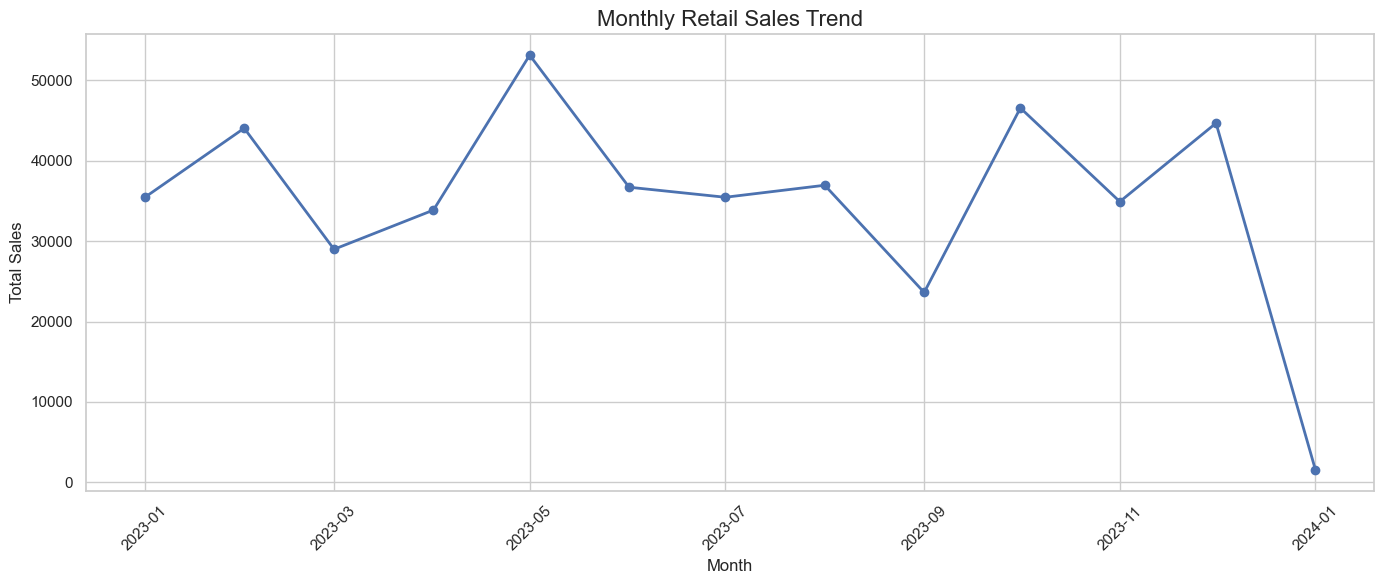

In [11]:
# Aggregate sales by month
monthly_sales = (
    df.set_index("Date")["Total Amount"]
      .resample("MS")
      .sum()
)

# Plot monthly sales
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Retail Sales Trend", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [12]:
if not monthly_sales.empty:
    print("Highest Sales Month:")
    print(monthly_sales.idxmax().strftime("%B %Y"))
    print("Sales:", monthly_sales.max())

    print("\nLowest Sales Month:")
    print(monthly_sales.idxmin().strftime("%B %Y"))
    print("Sales:", monthly_sales.min())

Highest Sales Month:
May 2023
Sales: 53150

Lowest Sales Month:
January 2024
Sales: 1530


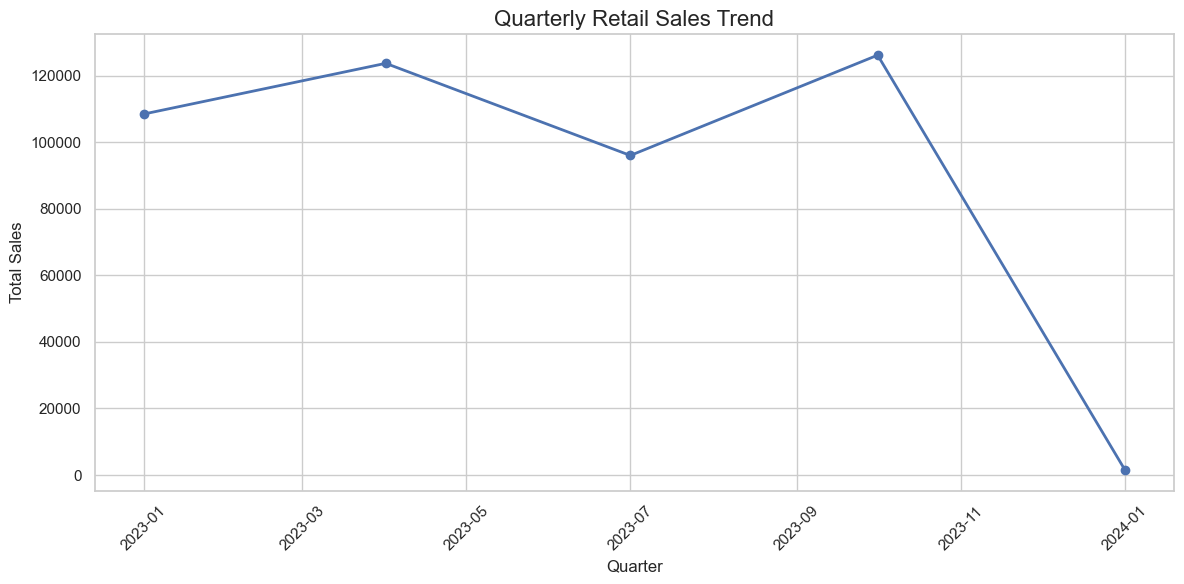

In [13]:
# Aggregate sales by quarter
quarterly_sales = (
    df.set_index("Date")["Total Amount"]
      .resample("QS")
      .sum()
)

# Plot quarterly sales
plt.figure(figsize=(12, 6))

plt.plot(
    quarterly_sales.index,
    quarterly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Quarterly Retail Sales Trend", fontsize=16)
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

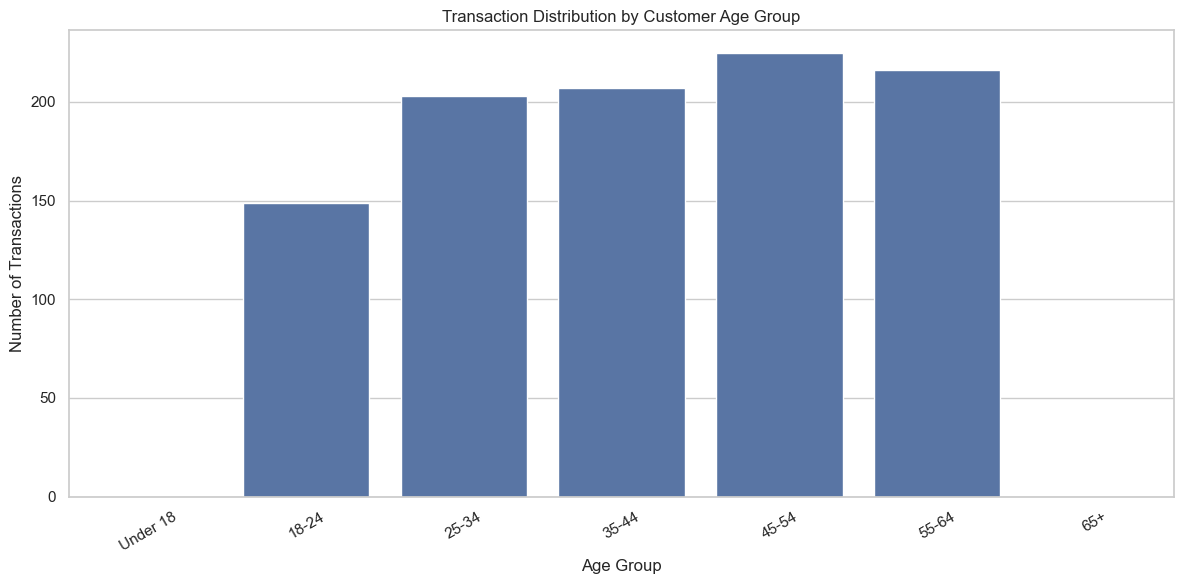

In [14]:
# Count transactions by age group
age_distribution = (
    df["Age Group"]
    .value_counts(sort=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=age_distribution.index.astype(str),
    y=age_distribution.values
)

plt.title("Transaction Distribution by Customer Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Transactions")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

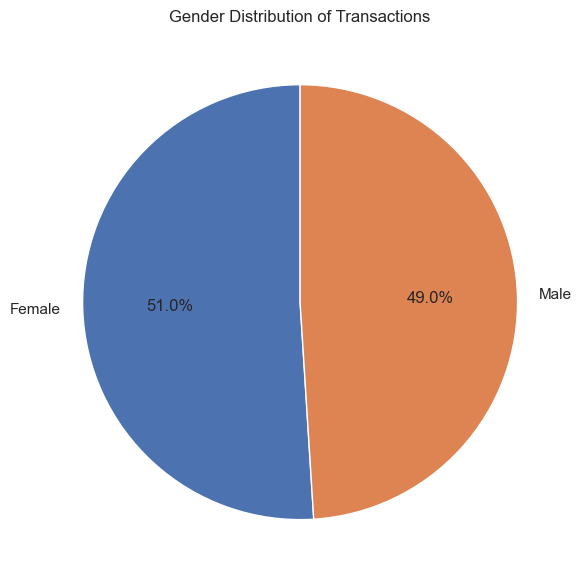

In [15]:
# Count transactions by gender
gender_counts = df["Gender"].value_counts()

plt.figure(figsize=(8, 6))

plt.pie(
    gender_counts.values,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Gender Distribution of Transactions")

plt.tight_layout()
plt.show()

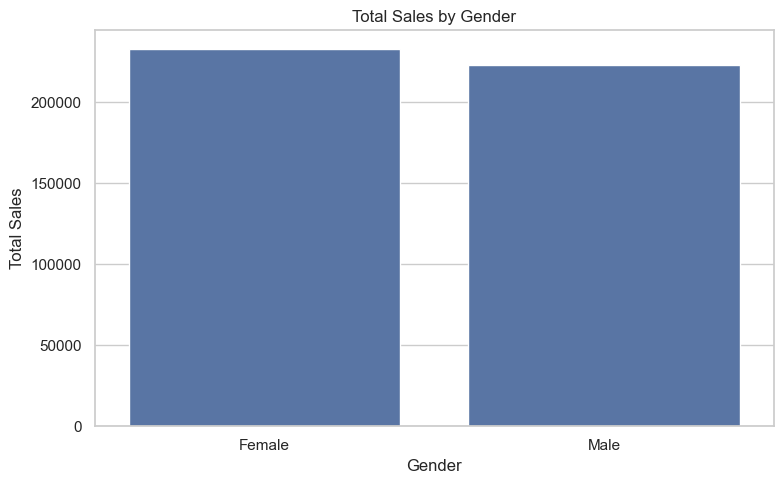

,Total Sales
Gender,
Female,232840
Male,223160


In [16]:
gender_sales = (
    df.groupby("Gender", observed=True)["Total Amount"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=gender_sales.index,
    y=gender_sales.values
)

plt.title("Total Sales by Gender")
plt.xlabel("Gender")
plt.ylabel("Total Sales")

plt.tight_layout()
plt.show()

display(gender_sales.to_frame("Total Sales"))

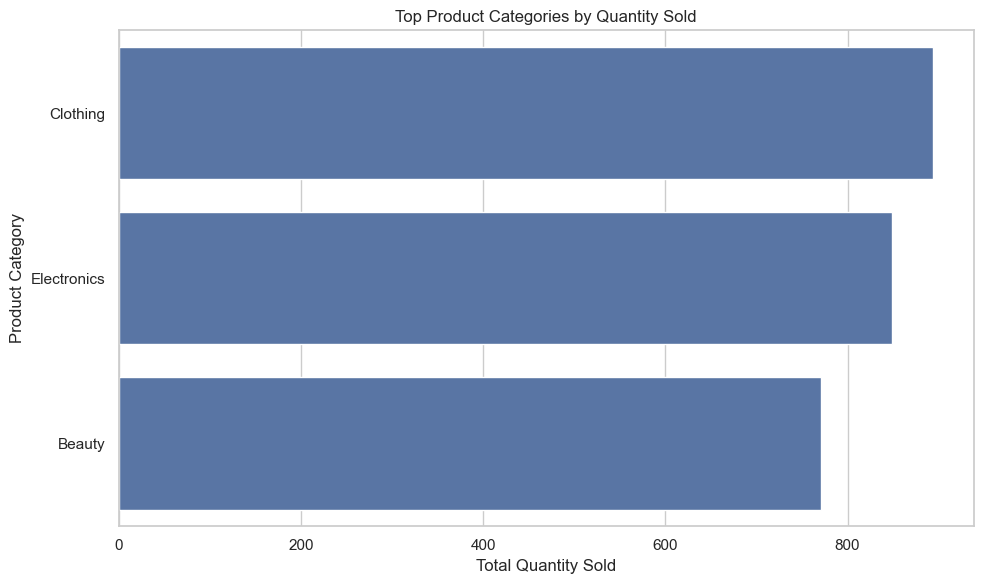

,Quantity Sold
Product Category,
Clothing,894
Electronics,849
Beauty,771


In [17]:
# Calculate quantity sold by product category
category_quantity = (
    df.groupby("Product Category", observed=True)["Quantity"]
      .sum()
      .sort_values(ascending=False)
)

# Select the top 10 categories
# The dataset contains fewer than 10 distinct categories,
# so this displays all available categories.
top_categories = category_quantity.head(10)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=top_categories.values,
    y=top_categories.index
)

plt.title("Top Product Categories by Quantity Sold")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

display(top_categories.to_frame("Quantity Sold"))

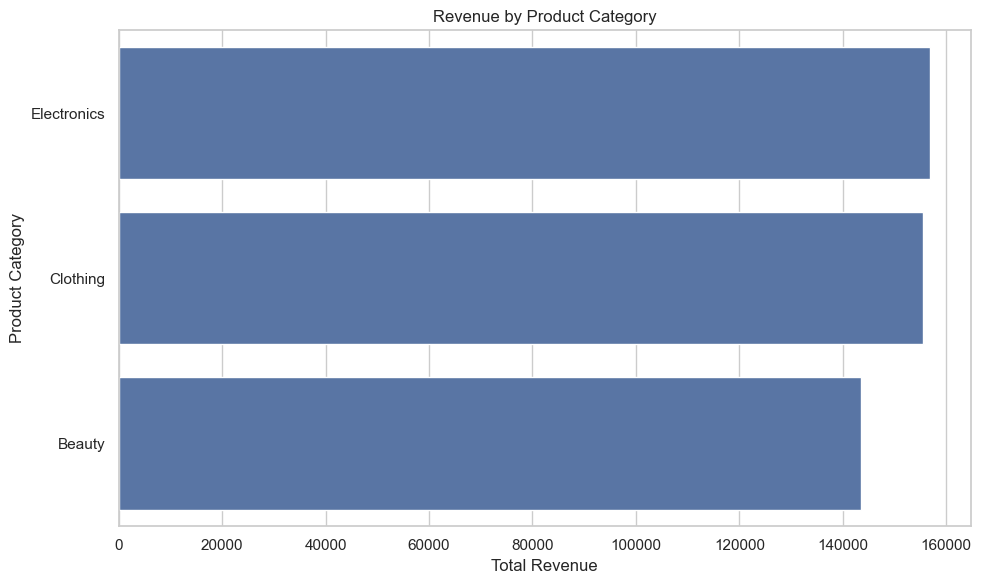

,Total Revenue
Product Category,
Electronics,156905
Clothing,155580
Beauty,143515


In [18]:
# Calculate revenue by category
category_revenue = (
    df.groupby("Product Category", observed=True)["Total Amount"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=category_revenue.values,
    y=category_revenue.index
)

plt.title("Revenue by Product Category")
plt.xlabel("Total Revenue")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

display(category_revenue.to_frame("Total Revenue"))

In [19]:
category_comparison = df.groupby(
    "Product Category",
    observed=True
).agg(
    Total_Quantity=("Quantity", "sum"),
    Total_Revenue=("Total Amount", "sum"),
    Average_Transaction_Amount=("Total Amount", "mean"),
    Transaction_Count=("Transaction ID", "count")
).sort_values(
    "Total_Revenue",
    ascending=False
)

display(category_comparison.round(2))

,Total_Quantity,Total_Revenue,Average_Transaction_Amount,Transaction_Count
Product Category,,,,
Electronics,849,156905,458.79,342
Clothing,894,155580,443.25,351
Beauty,771,143515,467.48,307


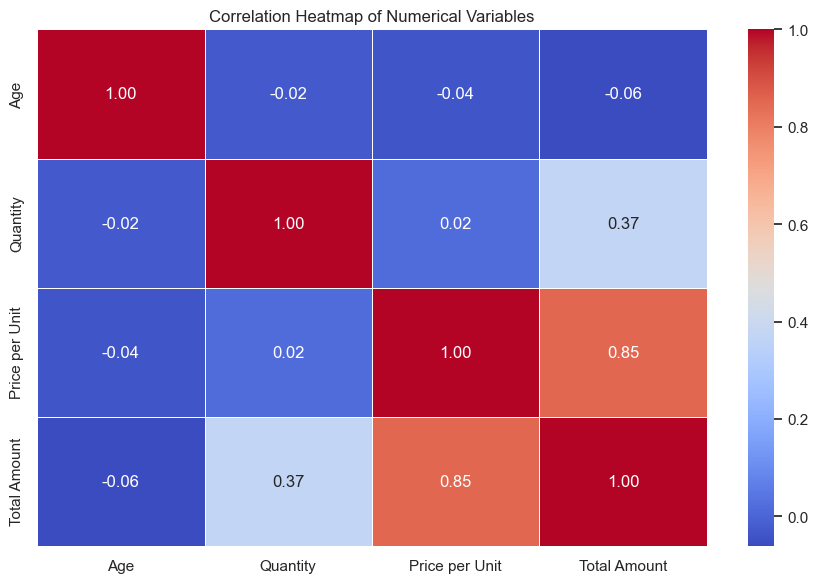

In [20]:
# Select relevant numerical variables
correlation_columns = [
    "Age",
    "Quantity",
    "Price per Unit",
    "Total Amount"
]

correlation_matrix = df[correlation_columns].corr()

# Plot correlation heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Variables")

plt.tight_layout()
plt.show()

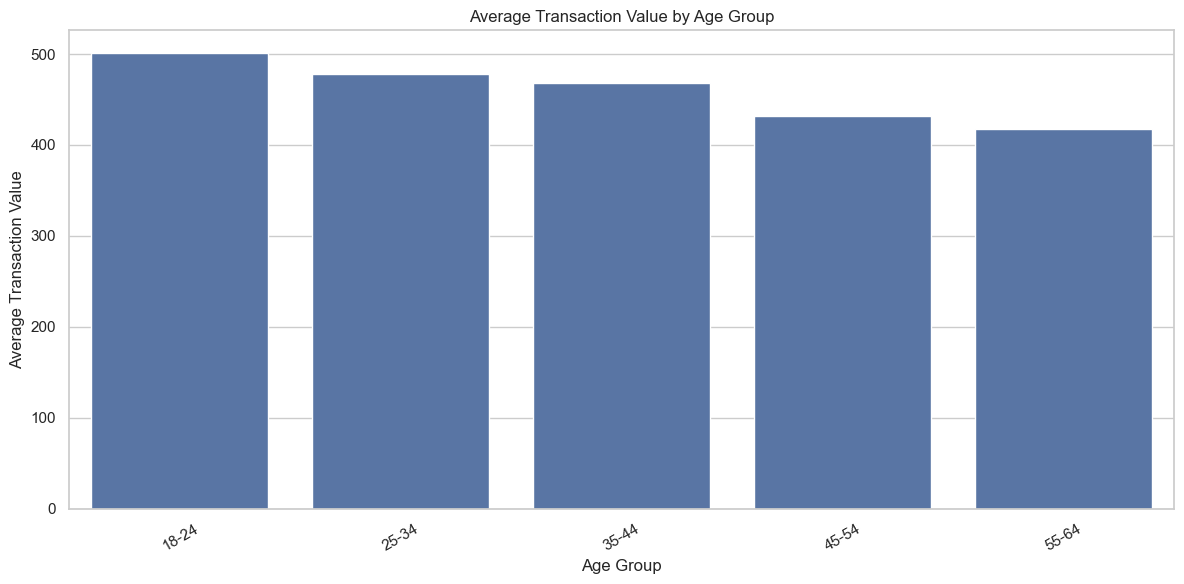

,Average Transaction Value
Age Group,
18-24,501.01
25-34,478.28
35-44,467.80
45-54,432.16
55-64,417.55


In [21]:
# Calculate average transaction value by age group
age_group_sales = (
    df.groupby("Age Group", observed=True)["Total Amount"]
      .mean()
      .sort_values(ascending=False)
)

plt.figure(figsize=(12, 6))

sns.barplot(
    x=age_group_sales.index.astype(str),
    y=age_group_sales.values
)

plt.title("Average Transaction Value by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Average Transaction Value")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(
    age_group_sales.to_frame("Average Transaction Value").round(2)
)

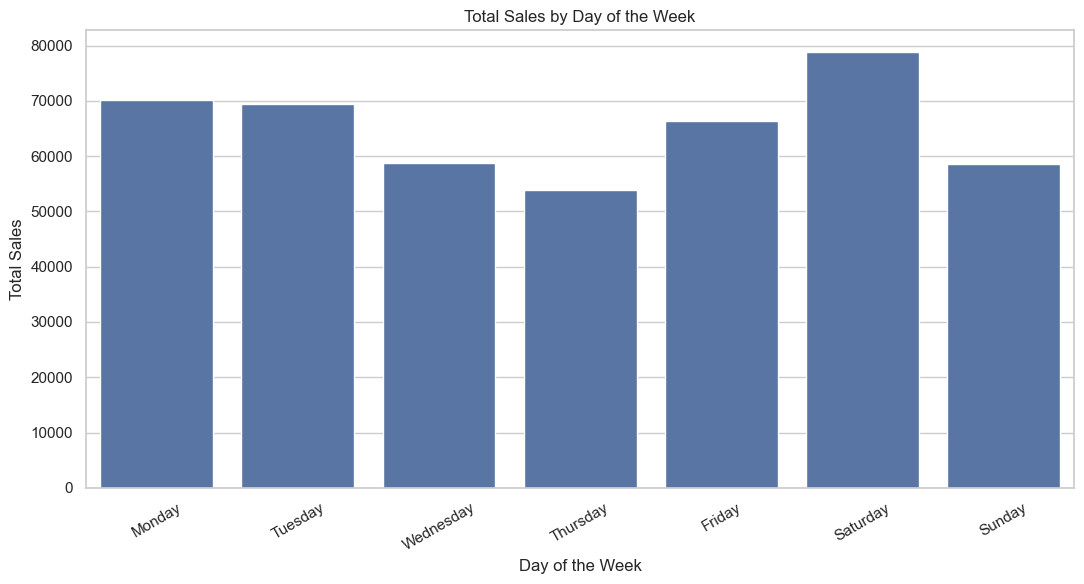

,Total Sales
Day of Week,
Monday,70250
Tuesday,69440
Wednesday,58770
Thursday,53835
Friday,66290
Saturday,78815
Sunday,58600


In [22]:
# Define the correct weekday order
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

# Aggregate sales by day of the week
weekday_sales = (
    df.groupby("Day of Week")["Total Amount"]
      .sum()
      .reindex(weekday_order)
)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=weekday_sales.index,
    y=weekday_sales.values
)

plt.title("Total Sales by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Total Sales")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(weekday_sales.to_frame("Total Sales"))

In [23]:
# Overall metrics
total_revenue = df["Total Amount"].sum()

total_transactions = df["Transaction ID"].nunique()

total_customers = df["Customer ID"].nunique()

average_transaction_value = df["Total Amount"].mean()

total_quantity_sold = df["Quantity"].sum()

print("RETAIL SALES SUMMARY")
print("-" * 40)

print(f"Total Revenue: {total_revenue:,.2f}")

print(f"Unique Transactions: {total_transactions:,}")

print(f"Unique Customers: {total_customers:,}")

print(f"Average Transaction Value: {average_transaction_value:,.2f}")

print(f"Total Quantity Sold: {total_quantity_sold:,}")

RETAIL SALES SUMMARY
----------------------------------------
Total Revenue: 456,000.00
Unique Transactions: 1,000
Unique Customers: 1,000
Average Transaction Value: 456.00
Total Quantity Sold: 2,514


In [24]:
print("Category with Highest Revenue:")
print(category_revenue.idxmax())
print(f"Revenue: {category_revenue.max():,.2f}")

print("\nCategory with Highest Quantity Sold:")
print(category_quantity.idxmax())
print(f"Quantity: {category_quantity.max():,.0f}")

Category with Highest Revenue:
Electronics
Revenue: 156,905.00

Category with Highest Quantity Sold:
Clothing
Quantity: 894


In [25]:
if not age_group_sales.empty:
    print("Age Group with Highest Average Transaction Value:")
    print(age_group_sales.idxmax())
    print(
        f"Average Transaction Value: "
        f"{age_group_sales.max():,.2f}"
    )

Age Group with Highest Average Transaction Value:
18-24
Average Transaction Value: 501.01
